In [2]:
!pip install easyocr opencv-python-headless matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.6/300.6 kB 19.4 MB/s eta 0:00:00


Warming up GPU...

--- Starting Benchmark [GPU=True] ---
Processing 8 stores...


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Initialization Time: 4.6006s
Inference Time:      6.7076s
Total Time:          11.3081s

================ BENCHMARK RESULTS ================

--- Starting Benchmark [GPU=False] ---
Processing 8 stores...
Initialization Time: 2.2636s
Inference Time:      145.3999s
Total Time:          147.6635s

--- Starting Benchmark [GPU=True] ---
Processing 8 stores...
Initialization Time: 2.2357s
Inference Time:      5.7780s
Total Time:          8.0137s

================ SUMMARY ================
CPU Inference Time: 145.3999s
GPU Inference Time: 5.7780s
Speedup Factor:     25.16x


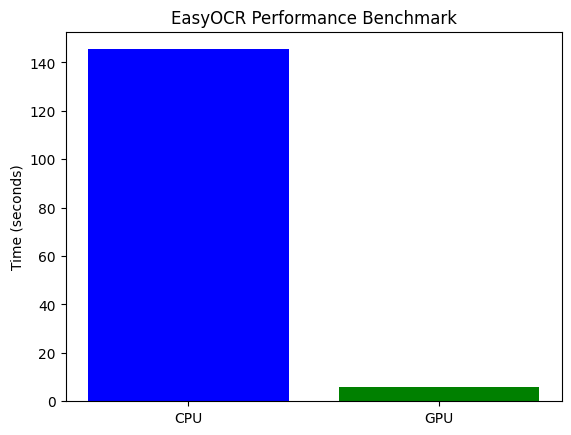

In [3]:
import cv2
import numpy as np
import easyocr
import os
import time
import matplotlib.pyplot as plt

# --- 1. Setup Dummy Data (So the code runs immediately) ---
# Skip this block if you are uploading your actual files
def generate_dummy_data():
    os.makedirs("Original Images", exist_ok=True)
    os.makedirs("Wall Bitmap", exist_ok=True)

    # Create a dummy wall bitmap (Black background, White stores)
    h, w = 1000, 1000
    walls = np.zeros((h, w), dtype=np.uint8)
    # Draw some "store" rectangles
    cv2.rectangle(walls, (100, 100), (300, 300), 255, -1)
    cv2.rectangle(walls, (400, 100), (600, 300), 255, -1)
    cv2.rectangle(walls, (100, 400), (300, 600), 255, -1)
    cv2.rectangle(walls, (400, 400), (600, 600), 255, -1)

    # Create a dummy color image with text
    original = np.ones((h, w, 3), dtype=np.uint8) * 255
    font = cv2.FONT_HERSHEY_SIMPLEX
    # Put text inside the "store" locations
    cv2.putText(original, "STORE A", (150, 200), font, 1, (0, 0, 0), 2)
    cv2.putText(original, "STORE B", (450, 200), font, 1, (0, 0, 0), 2)
    cv2.putText(original, "STORE C", (150, 500), font, 1, (0, 0, 0), 2)
    cv2.putText(original, "STORE D", (450, 500), font, 1, (0, 0, 0), 2)

    cv2.imwrite("Original Images/-1.jpg", original)
    cv2.imwrite("Wall Bitmap/-1_walls_bitmask_better.png", walls) # Inverted for your logic

generate_dummy_data()

# --- 2. Your Original Functions (Optimized for Benchmarking) ---

def preprocess_crop_for_ocr(crop_img):
    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    scale_factor = 2
    if gray.shape[0] * gray.shape[1] < 5000:
        scale_factor = 3
    width = int(gray.shape[1] * scale_factor)
    height = int(gray.shape[0] * scale_factor)
    upscaled = cv2.resize(gray, (width, height), interpolation=cv2.INTER_LANCZOS4)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(upscaled)
    _, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    return binary

def run_benchmark(original_path, wall_bitmap_path, use_gpu=True):
    """
    Modified version of your process function to measure time.
    """
    print(f"\n--- Starting Benchmark [GPU={use_gpu}] ---")

    # 1. Load Images (IO Time - usually excluded from AI benchmark, but kept for realism)
    img_original = cv2.imread(original_path)
    img_walls = cv2.imread(wall_bitmap_path, cv2.IMREAD_GRAYSCALE)

    if img_original.shape[:2] != img_walls.shape[:2]:
        img_walls = cv2.resize(img_walls, (img_original.shape[1], img_original.shape[0]))

    # 2. Pre-processing (CPU Bound)
    h, w = img_walls.shape
    mask_flood = np.zeros((h + 2, w + 2), np.uint8)
    im_floodfill = img_walls.copy()
    cv2.floodFill(im_floodfill, mask_flood, (0, 0), 255)
    stores_mask = cv2.bitwise_not(im_floodfill)
    contours, _ = cv2.findContours(stores_mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    # Filter contours to simulate work
    valid_contours = [c for c in contours if cv2.contourArea(c) > 1000]
    print(f"Processing {len(valid_contours)} stores...")

    # --- START TIMER ---
    # We load the reader inside the timer to measure Initialization + Inference
    # Or move it outside to measure ONLY Inference.
    # Usually, initialization happens once, so let's time them separately.

    t_start_init = time.perf_counter()
    reader = easyocr.Reader(['en'], gpu=use_gpu)
    t_end_init = time.perf_counter()

    t_start_inference = time.perf_counter()

    for i, cnt in enumerate(valid_contours):
        x, y, w, h = cv2.boundingRect(cnt)

        # Crop Logic
        single_store_mask = np.zeros_like(img_walls)
        cv2.drawContours(single_store_mask, [cnt], -1, 255, thickness=cv2.FILLED)
        crop_mask = single_store_mask[y:y+h, x:x+w]
        crop_original = img_original[y:y+h, x:x+w]
        final_crop = np.ones_like(crop_original) * 255
        final_crop[crop_mask == 255] = crop_original[crop_mask == 255]

        # Preprocess
        ocr_ready_img = preprocess_crop_for_ocr(final_crop)

        # Heavy OCR Work (Run 4x per store as per your logic)
        # Note: In a real benchmark, we might run just one for speed,
        # but here we replicate your exact load.
        _ = reader.readtext(ocr_ready_img, detail=0)

        rotated_img = cv2.rotate(final_crop, cv2.ROTATE_90_CLOCKWISE)
        ocr_ready_img_2 = preprocess_crop_for_ocr(rotated_img)
        _ = reader.readtext(ocr_ready_img_2, detail=0)

        _ = reader.readtext(final_crop, detail=0)

        rotated_img_2 = cv2.rotate(final_crop, cv2.ROTATE_90_CLOCKWISE)
        _ = reader.readtext(rotated_img_2, detail=0)

    t_end_inference = time.perf_counter()
    # --- END TIMER ---

    init_time = t_end_init - t_start_init
    infer_time = t_end_inference - t_start_inference
    total_time = init_time + infer_time

    print(f"Initialization Time: {init_time:.4f}s")
    print(f"Inference Time:      {infer_time:.4f}s")
    print(f"Total Time:          {total_time:.4f}s")

    return infer_time

# --- 3. Run Comparison ---

ORIGINAL_PATH = "1.png"
WALL_PATH = "Wall Bitmap/-1_walls_bitmask_better.png"

# Warmup Run (Optional but recommended for GPU to settle)
print("Warming up GPU...")
run_benchmark(ORIGINAL_PATH, WALL_PATH, use_gpu=True)

# Actual Benchmark
print("\n================ BENCHMARK RESULTS ================")
cpu_time = run_benchmark(ORIGINAL_PATH, WALL_PATH, use_gpu=False)
gpu_time = run_benchmark(ORIGINAL_PATH, WALL_PATH, use_gpu=True)

print("\n================ SUMMARY ================")
print(f"CPU Inference Time: {cpu_time:.4f}s")
print(f"GPU Inference Time: {gpu_time:.4f}s")

if gpu_time > 0:
    speedup = cpu_time / gpu_time
    print(f"Speedup Factor:     {speedup:.2f}x")

    # Simple Bar Chart
    plt.bar(['CPU', 'GPU'], [cpu_time, gpu_time], color=['blue', 'green'])
    plt.ylabel('Time (seconds)')
    plt.title('EasyOCR Performance Benchmark')
    plt.show()
else:
    print("Error in execution.")

Loading EasyOCR Model (Hardware Initialization)...

--- 1. Cold Start Analysis ---
Cold Start Inference Time: 2.2896 seconds

--- 2. Batch Processing Benchmarks (Warm State) ---
Processing Batch of 1 image(s)...
  > Total Time: 2.2409s
  > Avg Time per Image: 2.2409s
Processing Batch of 2 image(s)...
  > Total Time: 4.5042s
  > Avg Time per Image: 2.2521s
Processing Batch of 4 image(s)...
  > Total Time: 8.7640s
  > Avg Time per Image: 2.1910s


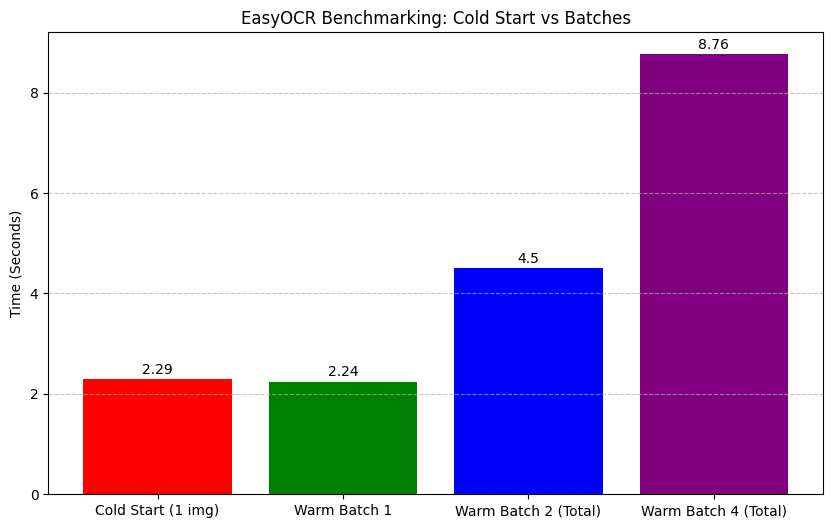

In [4]:
import time
import easyocr
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os

# --- Configuration ---
# Ensure these files are uploaded to your Colab environment
IMAGE_FILES = ["0.png", "1.png", "2.png", "3.png"]

def run_benchmark():
    # 1. Check if images exist
    for img in IMAGE_FILES:
        if not os.path.exists(img):
            print(f"Error: File {img} not found. Please upload it.")
            return

    print("Loading EasyOCR Model (Hardware Initialization)...")
    # This initializes the class, but often the CUDA context is fully lazy-loaded
    # only upon the first actual inference call.
    reader = easyocr.Reader(['en'], gpu=True)

    # Storage for results
    results = {
        'cold_start': 0,
        'batch_1': 0,
        'batch_2': 0,
        'batch_4': 0
    }

    print("\n--- 1. Cold Start Analysis ---")
    # The very first inference call triggers CUDA context creation and model weight loading to VRAM.
    start_time = time.perf_counter()
    _ = reader.readtext(IMAGE_FILES[0]) # Run on first image
    end_time = time.perf_counter()

    results['cold_start'] = end_time - start_time
    print(f"Cold Start Inference Time: {results['cold_start']:.4f} seconds")

    print("\n--- 2. Batch Processing Benchmarks (Warm State) ---")
    # Now the GPU is 'warm'. We benchmark different batch sizes.

    batches_to_test = [1, 2, 4]

    for batch_size in batches_to_test:
        current_batch = IMAGE_FILES[:batch_size] # Select first N images
        print(f"Processing Batch of {batch_size} image(s)...")

        start_time = time.perf_counter()

        # We simulate a batch by processing them sequentially in a loop.
        # Note: EasyOCR's readtext() is blocking, so real parallel batching
        # requires the hidden .readtext_batched() method or multithreading,
        # but this measures standard throughput.
        for img_path in current_batch:
            _ = reader.readtext(img_path)

        end_time = time.perf_counter()
        total_time = end_time - start_time

        results[f'batch_{batch_size}'] = total_time
        print(f"  > Total Time: {total_time:.4f}s")
        print(f"  > Avg Time per Image: {total_time/batch_size:.4f}s")

    # --- 3. Visualization ---
    names = ['Cold Start (1 img)', 'Warm Batch 1', 'Warm Batch 2 (Total)', 'Warm Batch 4 (Total)']
    times = [
        results['cold_start'],
        results['batch_1'],
        results['batch_2'],
        results['batch_4']
    ]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(names, times, color=['red', 'green', 'blue', 'purple'])

    # Add labels
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, round(yval, 2), ha='center', va='bottom')

    plt.title('EasyOCR Benchmarking: Cold Start vs Batches')
    plt.ylabel('Time (Seconds)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

if __name__ == "__main__":
    run_benchmark()

Starting Full Benchmark...

--- Benchmarking Device: CPU ---
Initializing CPU Engine...
Warming up...
  Running Batch Size: 1
    > Total: 36.5017s | Avg/Img: 36.5017s
  Running Batch Size: 2
    > Total: 73.2251s | Avg/Img: 36.6126s
  Running Batch Size: 4
    > Total: 143.6277s | Avg/Img: 35.9069s

--- Benchmarking Device: GPU ---
Initializing GPU Engine...
Warming up...
  Running Batch Size: 1
    > Total: 2.6009s | Avg/Img: 2.6009s
  Running Batch Size: 2
    > Total: 4.4296s | Avg/Img: 2.2148s
  Running Batch Size: 4
    > Total: 9.1467s | Avg/Img: 2.2867s

Plotting Results...


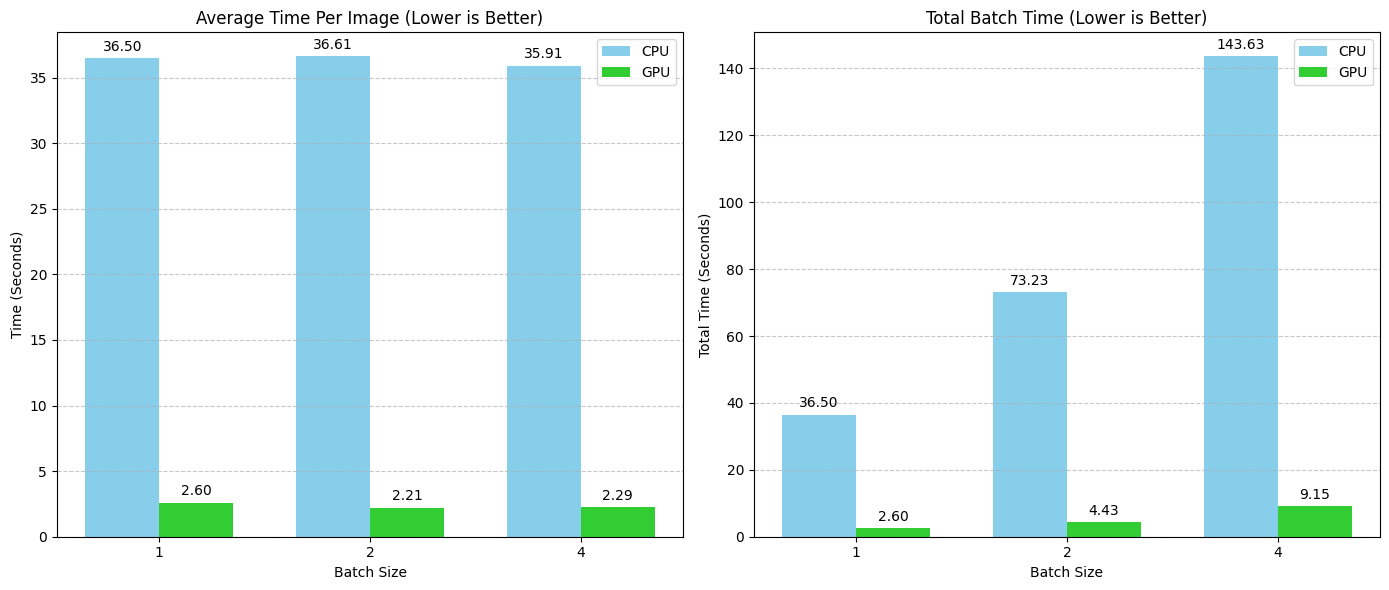

In [4]:
import time
import easyocr
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2

# --- Configuration ---
IMAGE_FILES = ["0.png", "1.png", "2.png", "3.png"]
BATCH_SIZES = [1, 2, 4]

# --- Helper: Generate Dummy Data if missing (For safety) ---
def ensure_images_exist():
    for img_name in IMAGE_FILES:
        if not os.path.exists(img_name):
            print(f"Generating dummy image for {img_name}...")
            # Create a 2000x2000 dummy image with text
            dummy = np.ones((2000, 2000, 3), dtype=np.uint8) * 255
            cv2.putText(dummy, "STORE NAME", (500, 500), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 0, 0), 5)
            cv2.imwrite(img_name, dummy)

ensure_images_exist()

# --- Benchmarking Function ---
def benchmark_device(device_type, batch_sizes, images):
    print(f"\n--- Benchmarking Device: {device_type.upper()} ---")

    # 1. Initialization (Excluded from batch timing)
    print(f"Initializing {device_type.upper()} Engine...")
    use_gpu = (device_type == 'gpu')
    reader = easyocr.Reader(['en'], gpu=use_gpu)

    # 2. Warmup (Crucial for GPU to settle)
    print("Warming up...")
    reader.readtext(images[0])

    results_total = []
    results_avg = []

    # 3. Run Batches
    for b_size in batch_sizes:
        current_batch = images[:b_size]
        print(f"  Running Batch Size: {b_size}")

        start_time = time.perf_counter()

        # Simulate batch processing
        for img in current_batch:
            _ = reader.readtext(img)

        end_time = time.perf_counter()

        total_time = end_time - start_time
        avg_time = total_time / b_size

        results_total.append(total_time)
        results_avg.append(avg_time)

        print(f"    > Total: {total_time:.4f}s | Avg/Img: {avg_time:.4f}s")

    return results_total, results_avg

# --- Main Execution ---
print("Starting Full Benchmark...")

# 1. Run CPU Benchmark
cpu_total, cpu_avg = benchmark_device('cpu', BATCH_SIZES, IMAGE_FILES)

# 2. Run GPU Benchmark
gpu_total, gpu_avg = benchmark_device('gpu', BATCH_SIZES, IMAGE_FILES)

# --- Plotting Results ---
print("\nPlotting Results...")

x = np.arange(len(BATCH_SIZES))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Average Time Per Image
rects1 = ax1.bar(x - width/2, cpu_avg, width, label='CPU', color='skyblue')
rects2 = ax1.bar(x + width/2, gpu_avg, width, label='GPU', color='limegreen')

ax1.set_ylabel('Time (Seconds)')
ax1.set_xlabel('Batch Size')
ax1.set_title('Average Time Per Image (Lower is Better)')
ax1.set_xticks(x)
ax1.set_xticklabels(BATCH_SIZES)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Total Batch Processing Time
rects3 = ax2.bar(x - width/2, cpu_total, width, label='CPU', color='skyblue')
rects4 = ax2.bar(x + width/2, gpu_total, width, label='GPU', color='limegreen')

ax2.set_ylabel('Total Time (Seconds)')
ax2.set_xlabel('Batch Size')
ax2.set_title('Total Batch Time (Lower is Better)')
ax2.set_xticks(x)
ax2.set_xticklabels(BATCH_SIZES)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Label bars
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1, ax1)
autolabel(rects2, ax1)
autolabel(rects3, ax2)
autolabel(rects4, ax2)

plt.tight_layout()
plt.show()